<a href="https://colab.research.google.com/github/hbprosper/dihiggs/blob/main/code/heft_laplace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Higgs Effective Field Theory (HEFT) Study: a Mixture of Laplace Approximations
> Created: Oct 31, 2026 Harrison B. Prosper and Claude<br>

## Introduction

The Markov chains of `heft_train_bnn.ipynb` gave posterior widths of only 0.5% of the POWHEG noise, far too small (`docs/bnn/bnn_plan2.pdf`). This notebook approximates the posterior instead by a **mixture of Gaussians**, one about each of the 20 networks of the fine-tuned ensemble, each obtained by **linearising** the network about that point (MacKay's Laplace approximation). It needs no sampling. The method is explained in detail in `docs/bnn/laplace_explained.pdf`; in brief:

* **One network.** Near a trained network $\hat w$, $f(x; w) \approx f(x;\hat w) + j(x)^T (w - \hat w)$ with $j = \partial f/\partial w$. With a Gaussian likelihood of known variances $\sigma_k^2$ and a Gaussian prior with one precision $\tau_g$ per parameter tensor, the posterior is Gaussian with precision $H = G + \mathrm{diag}(\tau)$, where $G = \sum_k j_k j_k^T/\sigma_k^2$, and the prediction at $x$ has mean $f(x;\hat w)$ and variance $v(x) = j(x)^T H^{-1} j(x)$.
* **The prior precisions** $\tau_g$ are set by MacKay's evidence updates, $\tau_g = \gamma_g / \sum_{i\in g}\hat w_i^2$, where $\gamma_g$ counts the parameters of group $g$ that the data determine.
* **Twenty networks.** The predictive mean is the average of the 20 means; the predictive variance is the average of the 20 variances $v_m$ (*within*) plus the variance of the 20 means (*between*, the ensemble spread).
* **The noise** is the exact Poisson variance of the scaled event counts (`dihiggs/counts.py`): $\sigma_k^2 = q_s(t_k + q_s)$, with $q_s$ the weight of one event of spectrum $s$ and $t_k$ the POWHEG value; the extra $q_s^2$ (one event) keeps empty and nearly empty bins from getting a vanishing variance. It is the variance with which the networks were fine-tuned. The alternative, $q_s\max(f_k, q_s)$ from the prediction, is the textbook Poisson weight, but it gives an enormous weight to the handful of bins where a network predicts a negative or tiny value against a large count: in the first network, two such rows out of 274,152 contribute a quarter of the $\chi^2$ and would dominate $G$ in their directions.
* **HEFTNet's structure** $f = \sum_i C_i(\theta)\,a_i(m_{hh})$ makes all this fast and exact: only 80 Jacobians (one per $m_{hh}$ bin) are needed.

The model error of the network, which no posterior of this network can describe, is added at the end as in the paper's appendix, with a coefficient $a(m_{hh})$ determined on the training-file rows not used in the training.

In [1]:
import os, sys, time, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from dihiggs import heftnet as NN
from dihiggs import laplace as LA
from dihiggs import counts as CN

plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "sans-serif",
  "font.size": 12
})

## Switches

| switch | meaning |
| :--- | :--- |
| `ENSEMBLE` | the run folder of the ensemble whose networks are the expansion points |
| `MEMBERS` | `None` for all members, or a list of folder names, e.g. `['member_01']` |
| `VARIANCE_FROM` | `'data'`: $\sigma_k^2 = q_s(t_k + q_s)$, the variance with which the networks were fine-tuned; `'model'`: $q_s\max(f_k, q_s)$, the Poisson variance at the prediction (see the introduction) |
| `PRIOR` | `'evidence'` (MacKay's updates) or a number $c$: every $\tau_g$ set to $c$ times its evidence value |
| `CHECK_MEMBER` | the member used for the linearisation and prior-sensitivity checks |
| `N_CHECK` | number of parameter draws in the linearisation check |
| `SAVE_G` | save each network's $G$ (125 MB each, in double precision) |
| `REDO` | if False, a member whose results exist is not repeated |

In [2]:
ENSEMBLE      = 'runs/ENS_bootstrap_huber_d2_1'
MEMBERS       = None
VARIANCE_FROM = 'data'
PRIOR         = 'evidence'
CHECK_MEMBER  = 'member_01'
N_CHECK       = 200
SAVE_G        = False
REDO          = False
DEVICE        = 'cpu'       # the work is small; the CPU is fine

torch.set_num_threads(os.cpu_count())
OUTDIR = f'runs/LAPLACE_{os.path.basename(ENSEMBLE.rstrip("/"))}'
os.makedirs(OUTDIR, exist_ok=True)
members = sorted(d for d in os.listdir(ENSEMBLE) if d.startswith('member_'))
if MEMBERS is not None:
    members = [m for m in members if m in MEMBERS]
print(f'{len(members)} networks from {ENSEMBLE}; results in {OUTDIR}')

20 networks from runs/ENS_bootstrap_huber_d2_1; results in runs/LAPLACE_ENS_bootstrap_huber_d2_1


## The data and the exact noise

The training file: its rows, split as in `heft_train.ipynb` (86.4% training, 1.6% validation, 12% quick test). The counts and the event weight $q_s$ of every spectrum are recovered exactly, and the bins with no events, which were dropped from the file, are restored: under a Poisson likelihood an empty bin is information. The likelihood uses the training rows plus the restored empty bins; the quick-test rows are kept for the model-error coefficient; the 1,000 test spectra for validation.

In [3]:
df = pd.read_csv('../data/heft_wide_gauss_traindata_13TeV.csv.gz')
N = len(df)
train_size = int(0.864 * N)
test_size  = int(0.120 * N)
val_size   = N - train_size - test_size

counted, quanta = CN.recover_counts(df)
print(f'event counts recovered: largest deviation from an integer '
      f'{quanta.max_dev.max():.1e}; events in range: median '
      f'{quanta.n_events.median():.0f}, smallest {quanta.n_events.min():.0f}')

# the restored empty bins are the rows of add_empty_bins that were not in df
full = CN.add_empty_bins(counted)
empty = full[full['count'] == 0]
like_rows = pd.concat([counted.iloc[:train_size], empty], ignore_index=True)
quick = counted.iloc[train_size + val_size:]
print(f'likelihood rows: {len(like_rows)} ({len(empty)} empty bins); '
      f'quick-test rows: {len(quick)}')

def as_tensor(frame):
    # the inputs of HEFTNet, in double precision
    return torch.tensor(frame[NN.FEATURES].to_numpy(np.float64))

X_like, X_quick = as_tensor(like_rows), as_tensor(quick)
q_like  = like_rows['quantum'].to_numpy()
t_like  = like_rows[NN.TARGET].to_numpy()

# the 1,000 test spectra, one row per spectrum, one column per bin
spectra = pd.read_csv('../data/heft_wide_gauss_testdata_13TeV.csv')
bins    = [c for c in spectra.columns if c.isdigit()]
T_test  = spectra[bins].to_numpy(np.float64)
n_spec, n_bins = T_test.shape
counts_test, q_test, _ = CN.recover_counts_wide(T_test)
x_bins  = (np.arange(n_bins) + 0.5) / 100
mhh     = 255 + 1500 * x_bins
theta   = spectra[['klambda', 'CT', 'CTT', 'CGGH', 'CGGHH']].to_numpy(np.float32)
X_test  = torch.tensor(np.column_stack([np.tile(x_bins, n_spec),
                                        np.repeat(theta, n_bins, axis=0)]
                                       ).astype(np.float32).astype(np.float64))
# exact Poisson variance of every test bin (NaN for empty bins)
var_test = np.where(T_test > 0, T_test * q_test[:, None], np.nan)

event counts recovered: largest deviation from an integer 4.0e-04; events in range: median 39043, smallest 15031


likelihood rows: 275966 (1814 empty bins); quick-test rows: 38076


## One Laplace approximation per network

For each network: $G$ (eq. 3 of the explanation), MacKay's prior updates, the number of well-determined parameters $\gamma$, the eigenvalues of $H$, the predictions and their variances at the test spectra and the quick-test rows, and the Laplace evidence. Each network takes well under a minute on a laptop CPU.

In [4]:
def noise(f):
    # the noise variance of the likelihood rows, given the predictions f
    if VARIANCE_FROM == 'model':
        return CN.poisson_variance(like_rows, prediction=np.maximum(f, q_like))
    return q_like * (t_like + q_like)

def run_member(name):
    folder = f'{OUTDIR}/{name}'
    if os.path.exists(f'{folder}/summary.json') and not REDO:
        return
    os.makedirs(folder, exist_ok=True)
    t0 = time.time()
    model = NN.HEFTNet()
    model.load(f'{ENSEMBLE}/{name}/dihiggs_params.pth')
    lap = LA.Laplace(model, device=DEVICE)
    with torch.no_grad():
        f_like = lap.model(X_like).numpy()
    V = noise(f_like)
    lap.fit_hessian(X_like, V)
    lap.fit_prior()
    if PRIOR != 'evidence':
        lap.set_prior(lap.tau * float(PRIOR))
    gamma, gamma_g = lap.gamma()
    chi2 = float(np.sum((f_like - t_like)**2 / V))
    log_det_noise = float(np.sum(np.log(V))) if VARIANCE_FROM == 'model' else 0.0
    lnZ = lap.log_evidence(chi2, log_det_noise)
    eig = lap.eigenvalues().numpy()
    mu_t, v_t = lap.predict(X_test)
    mu_q, v_q = lap.predict(X_quick)
    np.savez(f'{folder}/predictions.npz',
             mu_test=mu_t.numpy(), v_test=v_t.numpy(),
             mu_quick=mu_q.numpy(), v_quick=v_q.numpy(), eigenvalues=eig)
    if SAVE_G:
        torch.save(lap.state(), f'{folder}/laplace_state.pth')
    summary = {'member': name, 'gamma': gamma, 'chi2': chi2,
               'chi2_per_row': chi2 / len(V), 'lnZ': lnZ,
               'tau': lap.tau.tolist(), 'gamma_g': gamma_g.tolist(),
               'eig_min': float(eig[0]), 'eig_max': float(eig[-1]),
               'seconds': time.time() - t0}
    json.dump(summary, open(f'{folder}/summary.json', 'w'), indent=1)
    print(f'{name}: gamma = {gamma:6.1f}, chi2/row = {chi2/len(V):.3f}, '
          f'ln Z = {lnZ:.1f}, {time.time() - t0:.0f} s', flush=True)

for name in members:
    run_member(name)

S = pd.DataFrame([json.load(open(f'{OUTDIR}/{m}/summary.json')) for m in members])
S[['member', 'gamma', 'chi2_per_row', 'lnZ', 'eig_min', 'eig_max', 'seconds']]

member_01: gamma =  414.7, chi2/row = 1.159, ln Z = -162269.9, 32 s


member_02: gamma =  316.4, chi2/row = 1.178, ln Z = -164512.5, 28 s


member_03: gamma =  503.0, chi2/row = 1.154, ln Z = -162014.6, 32 s


member_04: gamma =  399.9, chi2/row = 1.168, ln Z = -163484.4, 28 s


member_05: gamma =  350.5, chi2/row = 1.171, ln Z = -163632.4, 30 s


...

member_17: gamma =  389.6, chi2/row = 1.169, ln Z = -163614.0, 28 s


member_18: gamma =  411.5, chi2/row = 1.162, ln Z = -162715.6, 26 s


member_19: gamma =  390.7, chi2/row = 1.161, ln Z = -162482.6, 27 s


member_20: gamma =  458.9, chi2/row = 1.154, ln Z = -161774.1, 25 s


,member,gamma,chi2_per_row,lnZ,eig_min,eig_max,seconds
0,member_01,414.723028,1.158865,-162269.877064,0.168226,2.058853e+12,31.597726
1,member_02,316.443863,1.178061,-164512.511627,0.078646,3.249822e+12,28.341976
2,member_03,502.972103,1.154083,-162014.578617,0.204336,1.174286e+12,32.089303
3,member_04,399.905508,1.168373,-163484.364801,0.160283,1.932447e+12,28.440309
4,member_05,350.450703,1.171206,-163632.356757,0.168309,1.842038e+12,29.512173
5,member_06,392.367884,1.162820,-162732.391083,0.150734,2.070418e+12,27.056165
6,member_07,486.782543,1.153920,-161868.632320,0.133300,2.339170e+12,28.611201
7,member_08,460.950824,1.156206,-162063.028689,0.126677,1.254582e+12,28.359969
8,member_09,414.704150,1.167316,-163426.519274,0.116075,2.240207e+12,27.932670
9,member_10,495.709009,1.153087,-161742.240502,0.112303,1.665872e+12,28.447709


## The mixture

Equal weights (the plan, decision 4). The Laplace evidences are shown as a diagnostic: their spread, in units of $\ln Z$, says how unequal the weights would be if taken at face value.

In [5]:
P = [np.load(f'{OUTDIR}/{m}/predictions.npz') for m in members]
mu, var_tot, var_in, var_bet = LA.mixture([p['mu_test'] for p in P],
                                          [p['v_test'] for p in P])
shape = (n_spec, n_bins)
mu, var_tot, var_in, var_bet = [a.reshape(shape) for a in
                                (mu, var_tot, var_in, var_bet)]
lnZ = S['lnZ'].to_numpy()
print(f'ln Z: range {lnZ.max() - lnZ.min():.1f}; the largest '
      f'evidence weight would be {np.max(np.exp(lnZ - lnZ.max())) / np.sum(np.exp(lnZ - lnZ.max())):.2f}')

def ratio(v):
    # sqrt(v) / sigma, the width in units of the POWHEG noise
    return np.sqrt(v / var_test)

print(f'{"":22s} {"median width / noise":>22s}')
print(f'{"":22s} {"all":>7s} {"255-555":>8s} {">555":>6s}')
for label, v in [('within networks', var_in), ('between networks', var_bet),
                 ('total', var_tot)]:
    r = ratio(v)
    print(f'{label:22s} {np.nanmedian(r):7.3f} {np.nanmedian(r[:, :20]):8.3f} '
          f'{np.nanmedian(r[:, 20:]):6.3f}')

ln Z: range 5088.3; the largest evidence weight would be 1.00
                         median width / noise
                           all  255-555   >555
within networks          0.024    0.033  0.021
between networks         0.056    0.089  0.049
total                    0.061    0.096  0.053


## Checks on one network

**Linearisation.** Parameter draws from $N(\hat w, H^{-1})$ are evaluated with the *full* network and their spread compared with $\sqrt{v}$. Two versions: draws in all directions, and draws restricted to the directions the data determine (eigenvalues of $H$ above 100 times the largest $\tau_g$). In the directions left to the prior the parameters may move by amounts comparable to their own size, far outside the region where the network is linear, so the first version is expected to fail; what matters is the second, and the share of $v$ carried by each kind of direction.

**Prior.** The widths with every $\tau_g$ multiplied by 0.1 and by 10.

In [6]:
model = NN.HEFTNet()
model.load(f'{ENSEMBLE}/{CHECK_MEMBER}/dihiggs_params.pth')
lap = LA.Laplace(model)
with torch.no_grad():
    f_like = lap.model(X_like).numpy()
lap.fit_hessian(X_like, noise(f_like))
lap.fit_prior()
tau_ev = lap.tau.clone()

# 50 test spectra are enough for the checks
Xc = X_test[:50 * n_bins]
var_c = var_test[:50].reshape(-1)
mu_c, v_c = lap.predict(Xc)
J = lap.row_jacobian(Xc)                        # [rows, n]
lam, U = torch.linalg.eigh(lap.G + torch.diag(lap.tau[lap.group_index]))
share = (J @ U)**2 / lam                         # each direction's share of v
data_dirs = lam > 100 * float(lap.tau.max())
frac = (share[:, data_dirs].sum(1) / share.sum(1)).numpy()
print(f'{int(data_dirs.sum())} data-determined directions carry a median '
      f'{np.median(frac):.2f} of v')

gen = torch.Generator().manual_seed(1)
def spread(directions):
    # the spread of the full network over N_CHECK draws in the given directions
    Z = torch.randn(int(directions.sum()), N_CHECK, dtype=torch.float64,
                    generator=gen)
    D = (U[:, directions] / lam[directions].sqrt()) @ Z
    F = torch.stack([lap.evaluate(lap.w_hat + D[:, i], Xc) for i in range(N_CHECK)])
    v_lin = share[:, directions].sum(1)
    return (F.std(0) / v_lin.sqrt()).numpy()

for label, d in [('all directions', torch.ones_like(data_dirs)),
                 ('data-determined directions', data_dirs)]:
    r = spread(d)
    print(f'{label:28s}: full / linearised spread, median {np.median(r):.3g} '
          f'(10%: {np.percentile(r, 10):.3g}, 90%: {np.percentile(r, 90):.3g})')

for c in [0.1, 1.0, 10.0]:
    lap.set_prior(tau_ev * c)
    _, v = lap.predict(Xc)
    print(f'prior precisions x {c:4g}: median width / noise '
          f'{np.nanmedian(np.sqrt(v.numpy() / var_c)):.4f}')
lap.set_prior(tau_ev)

242 data-determined directions carry a median 0.52 of v


all directions              : full / linearised spread, median 4.83e+04 (10%: 2.18e+04, 90%: 1.14e+05)


data-determined directions  : full / linearised spread, median 1.01 (10%: 0.919, 90%: 1.13)


prior precisions x  0.1: median width / noise 0.0253


prior precisions x    1: median width / noise 0.0244


prior precisions x   10: median width / noise 0.0233


## The model error and the calibration

As in the appendix, a term $a(m_{hh})\,\sigma_k^2$ is added to the predictive variance. $a$ is determined bin by bin on the quick-test rows, by requiring $\langle z^2\rangle = 1$ with $z = (t - \bar\mu)/\sqrt{\sigma^2(1 + a) + s^2}$, now with $s^2$ the mixture variance, and smoothed with $a(m_{hh}) = a_0 e^{-(m_{hh} - 255)/\lambda} + a_1$. The test spectra are used only to check the result.

In [7]:
from scipy.optimize import brentq, least_squares

Pq = LA.mixture([p['mu_quick'] for p in P], [p['v_quick'] for p in P])
mu_q, s2_q = Pq[0], Pq[1]
t_q = quick[NN.TARGET].to_numpy()
var_q = t_q * quick['quantum'].to_numpy()
bin_q = np.rint(quick['mhh'].to_numpy() * 100 - 0.5).astype(int)

def a_of_bin(rows):
    r2, v, s2 = (t_q - mu_q)[rows]**2, var_q[rows], s2_q[rows]
    g = lambda a: np.mean(r2 / (v * (1 + a) + s2)) - 1
    return 0.0 if g(0) <= 0 else brentq(g, 0, 50)

a_bin = np.array([a_of_bin(bin_q == b) for b in range(n_bins)])
n_per_bin = np.bincount(bin_q, minlength=n_bins)
fit = least_squares(lambda p: (p[0] * np.exp(-(mhh - 255) / p[1]) + p[2] - a_bin)
                    * np.sqrt(n_per_bin), [0.6, 100, 0.08],
                    bounds=([0, 5, 0], [10, 2000, 1])).x
a_smooth = fit[0] * np.exp(-(mhh - 255) / fit[1]) + fit[2]
print(f'a(m) = {fit[0]:.3f} exp(-(m - 255)/{fit[1]:.0f} GeV) + {fit[2]:.3f}')

def pull_sd(v_pred, a=0.0):
    z = (T_test - mu) / np.sqrt(var_test * (1 + a) + v_pred)
    return np.nanstd(z), np.nanstd(z[:, :20]), np.nanstd(z[:, 20:]), z

print(f'{"":36s} {"s.d. of pull":>13s}  {"255-555":>8s} {">555":>6s} {"|z|<2":>7s}')
rows = [('ensemble spread only (between)', var_bet, 0.0),
        ('mixture (within + between)', var_tot, 0.0),
        ('mixture + model error a(m)', var_tot, a_smooth)]
Z = {}
for label, v, a in rows:
    sd, thr, rest, z = pull_sd(v, a)
    Z[label] = z
    print(f'{label:36s} {sd:13.3f}  {thr:8.3f} {rest:6.3f} '
          f'{np.nanmean(np.abs(z) < 2):7.3f}')

a(m) = 0.758 exp(-(m - 255)/76 GeV) + 0.109
                                      s.d. of pull   255-555   >555   |z|<2
ensemble spread only (between)               1.077     1.155  1.050   0.936
mixture (within + between)                   1.076     1.152  1.049   0.937
mixture + model error a(m)                   1.003     1.023  0.996   0.951


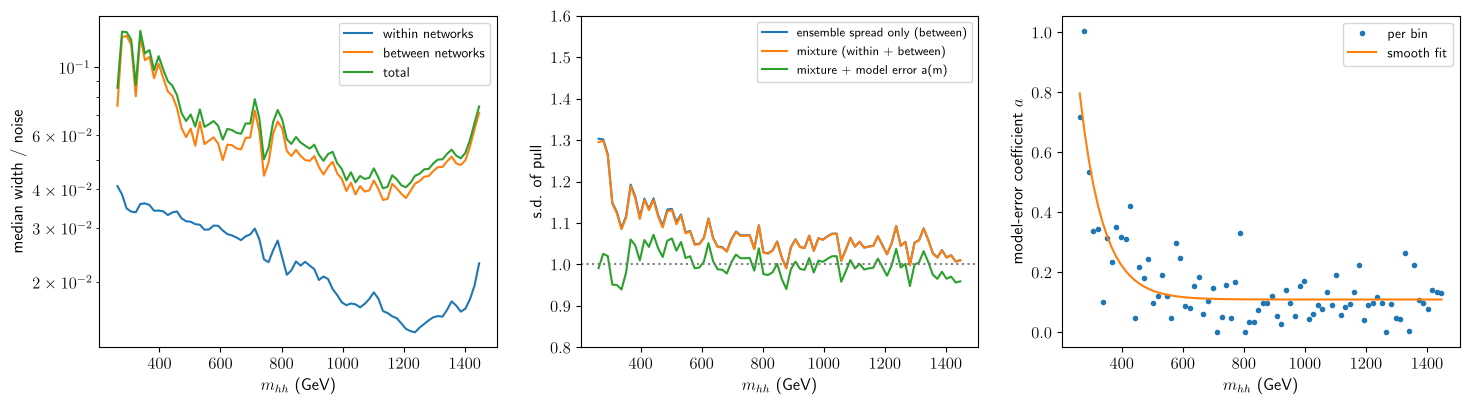

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for label, v in [('within networks', var_in), ('between networks', var_bet),
                 ('total', var_tot)]:
    ax[0].plot(mhh, np.nanmedian(ratio(v), axis=0), label=label)
ax[0].set_yscale('log'); ax[0].set_ylabel('median width / noise')
ax[0].legend(fontsize=10)
for label, z in Z.items():
    ax[1].plot(mhh, np.nanstd(z, axis=0), label=label)
ax[1].axhline(1, color='gray', ls=':'); ax[1].set_ylim(0.8, 1.6)
ax[1].set_ylabel('s.d. of pull'); ax[1].legend(fontsize=9)
ax[2].plot(mhh, a_bin, 'o', ms=3, label='per bin')
ax[2].plot(mhh, a_smooth, label='smooth fit')
ax[2].set_ylabel(r'model-error coefficient $a$'); ax[2].legend(fontsize=10)
for a in ax:
    a.set_xlabel(r'$m_{hh}$ (GeV)')
fig.tight_layout()
plt.savefig(f'{OUTDIR}/laplace_summary.png')
plt.show()